In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import root_numpy

Welcome to JupyROOT 6.22/02


In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def getData(branchNames, dfNames, inputFiles, treeName):
    data = root_numpy.root2array(inputFiles, treeName, branches=branchNames)
    return pd.DataFrame(data, columns=dfNames)

In [35]:
def flatten(data, column):
    a = []
    for row in range(0,len(data)):
        a.append(data[row][column])
    return np.concatenate(a)

In [36]:
def getFlattenedData(branchNames, dfNames, inputFiles, treeName):
    data = root_numpy.root2array(inputFiles, treeName, branches=branchNames)
    a = []
    for branchName in branchNames:
        a.append(flatten(data, branchNames.index(branchName)))
    return pd.DataFrame(np.transpose(a), columns=dfNames)

In [37]:
def getRc(dataframe):
    n_ss = dataframe[dataframe.bs==1].shape[0]
    n_os = dataframe[dataframe.bs==-1].shape[0]
    return (n_ss-n_os)/(n_ss+n_os)

In [53]:
observables2 = ['pt','m','b','dr','rg','zg','mg','weight']#,'evid','reject']
observabless2 = ['pts','ms','bs','drs','rgs','zgs','mgs','ws','evids','rejects']

In [54]:
df_uncut = getData(observables2, observables2, '$HOME/output/run12/pythia0412.root', 'ResultTree')

In [60]:
df_uncut

,pt,m,b,dr,rg,zg,mg,weight
0,[9.715593260088992],[1.4675522980854667],[0],[0.33790647432383236],[0.24725413018000417],[0.48965106953369847],[1.4675522980854667],1.437899e-08
1,[9.28189024136429],[4.324057725012185],[-1],[0.34049419056085556],[0.3905575412431371],[0.11841769038517684],[4.324057725012185],1.437899e-08
2,[11.141212143886642],[3.1464681431023296],[0],[0.397717540338856],[0.27749986462062004],[0.2828117129749508],[3.1464681431023296],1.437899e-08
3,[],[],[],[],[],[],[],1.437899e-08
4,[9.691873216967775],[2.6236422738997316],[1],[0.09801852058778572],[0.21535709679649742],[0.4189134946424562],[2.6236422738997316],1.437899e-08
...,...,...,...,...,...,...,...,...
3466838,[7.248244965985641],[2.6942413070544453],[0],[0.3813451808382519],[0.19374545673781893],[0.3322019248289842],[2.5049257252946715],1.946740e-08
3466839,[5.574697792567816],[1.9636317324059833],[0],[0.4656130293298296],[0.37263464500980725],[0.1601075936188958],[1.9636317324059833],1.946740e-08
3466840,[],[],[],[],[],[],[],1.946740e-08
3466841,[],[],[],[],[],[],[],1.946740e-08


In [57]:
empty = []
for irow in range(0,df_uncut.shape[0]):
    if (len(df_uncut.iloc[irow]['pt']) == 0):
        empty.append(irow)

In [58]:
len(empty)

3058294

In [59]:
df_uncut.shape[0]

3466843

In [ ]:
a = []
for column in observables2:
    for row in range(0,df_uncut.shape[0]):
        if (row not in empty):
            a.append(df_uncut.iloc[row][column])
df = pd.DataFrame(np.transpose(a), columns=observables2)

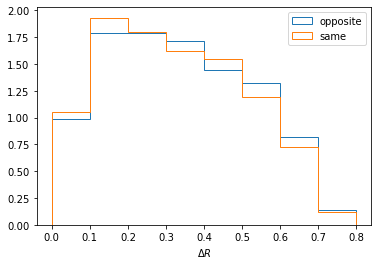

In [39]:
plt.hist(df[df.b<0]['dr'], histtype='step', label='opposite', bins=np.arange(0,0.9,0.1), density=True, weight=df[df.b<0]['weight'])
plt.hist(df[df.b>0]['dr'], histtype='step', label='same', bins=np.arange(0,0.9,0.1), density=True, weight=df[df.b>0]['weight'])
plt.xlabel('$\Delta R$')
plt.legend()

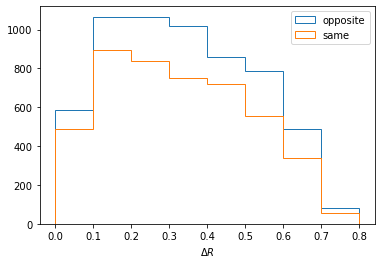

In [40]:
plt.hist(df[df.bs<0]['drs'], histtype='step', label='opposite', bins=np.arange(0,0.9,0.1))
plt.hist(df[df.bs>0]['drs'], histtype='step', label='same', bins=np.arange(0,0.9,0.1))
plt.xlabel('$\Delta R$')
plt.legend()

In [41]:
dredges = np.arange(0,0.9,0.1)
drcenter = np.arange(0.05,0.85,0.1)

In [42]:
dfs = []
for i in range(0, len(drcenter)):
    dfs.append(df[np.logical_and(df.drs>dredges[i], df.drs<dredges[i+1])])

In [43]:
rcs = []
for i in range(0, len(dfs)):
    rcs.append(getRc(dfs[i]))

In [44]:
rcs

[-0.09023255813953489,
 -0.0856269113149847,
 -0.12092534174553102,
 -0.15141242937853108,
 -0.08803039898670044,
 -0.17287630402384502,
 -0.18115942028985507,
 -0.19117647058823528]

Text(0.5, 0, '$\\Delta R$')

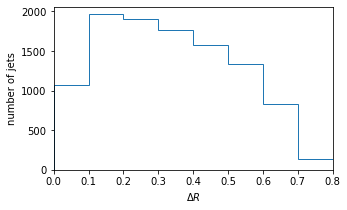

In [45]:
fig=plt.figure(figsize=(5,3))
plt.hist(df['drs'], bins=dredges, histtype='step')
plt.xlim(0,0.8)
plt.ylabel('number of jets')
plt.xlabel('$\Delta R$')

(-0.2, 0.0)

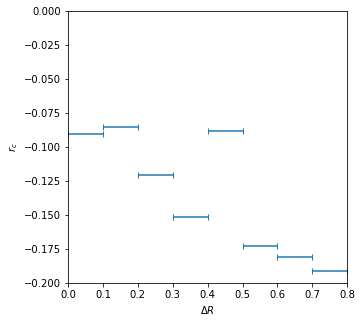

In [46]:
fig=plt.figure(figsize=(5,5))
plt.errorbar(drcenter, rcs, xerr=np.array(drcenter)-np.array(dredges[:-1]), ls='none', capsize=3)
plt.xlabel('$\Delta R$')
plt.ylabel('$r_c$')
plt.xlim(0,0.8)
plt.ylim(-0.2,0)